In [2]:
## building a basic deepagent
import os
from dotenv import load_dotenv

load_dotenv()
os.environ["GQO_API_KEY"] = os.getenv("GROQ_API_KEY")
if not os.getenv("Tavily_APT_KEY"):
    os.environ["Tavily_API_KEY"] = os.getenv("Tavily_API_KEY")



In [3]:
## websearch tool for deep agent
from tavily import TavilyClient
from typing import Literal
tavily_client = TavilyClient(api_key=os.getenv("Tavily_API_KEY"))

def web_search(query:str,max_results:int=2,topic: Literal["sports","news","finance","general"]="general",include_raw_content:bool=False):
    """search the web using tavily"""
    return tavily_client.search(
        query=query, max_results=max_results, topic=topic, include_raw_content = include_raw_content,
    )
    
    
result = web_search("What is LangGraph?", max_results=3)
print(result)


{'query': 'What is LangGraph?', 'follow_up_questions': None, 'answer': None, 'images': [], 'results': [{'url': 'https://www.geeksforgeeks.org/machine-learning/what-is-langgraph', 'title': 'What is LangGraph - GeeksforGeeks', 'content': 'LangGraph is an open-source framework from LangChain designed to build and manage AI agent workflows using graph-based structures. It allows developers to define workflows as nodes and edges, making complex agent interactions more structured, scalable and easier to control. [...] langgraph: Framework for building graph-based AI workflows.\n langchain: Popular toolkit for LLM-powered AI applications.\n google-generativeai: Google’s API for Generative AI (Gemini models).\n\n Python  ````\n! pip install langgraph langchain google - generativeai\n```` \n\n### Step 2: Setup Gemini API [...] ## Building a Simple Chatbot with LangGraph\n\nLangGraph makes it easy to build structured, stateful applications like chatbots. In this example we’ll learn how to create

In [4]:
## llm model 
from langchain.chat_models import init_chat_model

model= init_chat_model("groq:qwen/qwen3.8-27b")
model

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.13', 'langchain': '1.4.7'}}, client=<groq.resources.chat.completions.Completions object at 0x000001CA9B28ACF0>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000001CA9B28BA10>, model_name='qwen/qwen3.8-27b', model_kwargs={}, groq_api_key=SecretStr('**********'))

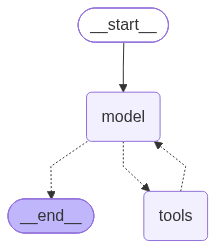

In [5]:
from langchain.agents import create_agent

agent = create_agent(
    model=model,
    tools = [web_search]
)
agent

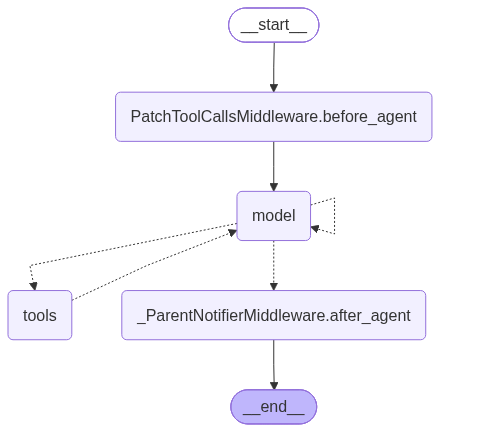

In [6]:
from deepagents import create_deep_agent

deepagent = create_deep_agent(
    model=model,
    tools=[web_search],
    system_prompt="Act as a researcher. Use web search when current information is required."
)
deepagent

In [8]:
res = deepagent.invoke({"messages":[{"role":"user","content":"what is deepagents. "}]})
res

{'messages': [HumanMessage(content='what is deepagents. ', additional_kwargs={}, response_metadata={}, id='2e55fba0-8723-46ae-9261-d4dde879e6f9'),
  AIMessage(content='', additional_kwargs={'tool_calls': [{'id': 'ep1vq2a5p', 'function': {'arguments': '{"query":"deepagents library what is it"}', 'name': 'web_search'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 31, 'prompt_tokens': 2862, 'total_tokens': 2893, 'completion_time': 0.092508529, 'completion_tokens_details': None, 'prompt_time': 0.19662006, 'prompt_tokens_details': None, 'queue_time': 0.059740416, 'total_time': 0.289128589}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_a1293f40b5', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a17d22-e54c-7246-8029-3383ba606ced-0', tool_calls=[{'name': 'web_search', 'args': {'query': 'deepagents library what is it'}, 'id': 'ep1vq2a5p', 'type': 'tool_call'}], invalid_tool_

In [9]:
print(res["messages"][-1].content)

**Deep Agents** (`deepagents`) is a standalone Python library built on top of LangChain and LangGraph for building LLM-powered agents.

Here's a breakdown of what it is and what it offers:

## Core Concept
- It's an **"agent harness"** — a higher-level API with opinionated defaults that sits on top of LangChain's core building blocks.
- It uses the **LangGraph runtime** under the hood for durable execution, streaming, and human-in-the-loop features.
- Think of it as a way to avoid reinventing the planner, filesystem/context layer, and subagent infrastructure from scratch.

## Key Built-In Capabilities
- **File systems** for context management
- **Subagent-spawning** — the ability to create and delegate to sub-agents
- **Long-term memory**
- Optional **task planning** and **skills**

## How to Use
- Install with `pip install deepagents`
- The central function is `create_deep_agent()`, which sets up an agent with these capabilities in a relatively simple call.

## Also Included
- A **ter